# Original-space FX: generalized Kent anisotropy pilot

**Question:** Does replacing the rotationally symmetric vMF direction distribution with a constrained generalized Kent distribution improve joint direction–magnitude modeling of the original FX data?

This experiment uses the original nine-dimensional FX return representation: **no spherical UMAP, PCA, sector hierarchy, or added context variables**. A date is a nine-coordinate vector; its normalized direction lies on $S^8$. $K$ denotes mixture components, not currencies or dimensions.

**Agreed grid: $K\in\{1,3,6,10\}$; ten starts per configuration.** All directional families share concentration and radial variance across components. The Kent family estimates a full component-specific tangent shape. This is the initial shared-parameter benchmark, not the later concentration/variance-sharing extension.

This notebook runs from this folder, `Thesis`, or its parent workspace with the existing `GMM/.venv` environment. All new artifacts stay in this folder. Original data and estimator helpers are reused without modification.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

cwd = Path.cwd().resolve()
candidates = [cwd, cwd / 'Kent mixture models', cwd / 'Thesis' / 'Kent mixture models']
archive = next((p for p in candidates if (p / 'kent_experiment.py').is_file()), None)
if archive is None:
    raise FileNotFoundError('Run from Kent mixture models, Thesis, or its parent workspace.')
sys.path.insert(0, str(archive))
import kent_experiment as experiment
import kent_report as report

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False})
data = experiment.b.load_data()['fx']
run_dir = experiment.run_directory(data)
display(pd.DataFrame(experiment.protocol(data)['splits']))
print('Run directory:', run_dir)
print('FX input hash:', experiment.protocol(data)['data_hash'])
print('Component grid:', experiment.km.GRID)


Run directory: /Users/shashwatroy/VSCode Projects/Thesis/Kent mixture models/results/a9f01047734a8126
FX input hash: 2f4919669d2799b67404aea86d4a4dd3c2ac0ae7632cae05606ca10ca56c64ef
Component grid: (1, 3, 6, 10)


,dataset,split,rows,dimensions,start,end
0,fx,train,4120,9,2000-01-03,2016-02-08
1,fx,validation,1373,9,2016-02-09,2021-06-22
2,fx,test,1374,9,2021-06-23,2026-10-30


## 1. Data, fixed baseline, and density measure

The frozen ECB dataset includes EUR and nine other currencies. Negative log changes in foreign-currency units per EUR represent currency appreciation against EUR. Cross-currency demeaning removes the common numeraire, and the original orthonormal Helmert basis produces nine coordinates of that subspace. Orthogonality does not imply statistical independence. This basis change is not a lossy dimensionality reduction. No feature standardization, volatility scaling, filling, or new data acquisition is performed.

The original chronological 60/20/20 boundaries are retained. Validation selects configurations; selected models are refitted on training plus validation (the **development sample**) before evaluation on the final period. That period has been inspected in earlier work, so this is retrospective evaluation.

For an original return vector $x\in\mathbb R^9$, write $r=\|x\|_2$, $u=x/r$, and $m=\log r$. A directional–magnitude model supplies a density relative to sphere surface area and $dm$. The Cartesian GMM supplies a density relative to $dx$. Because $dx=r^8dr\,d\omega=r^9dm\,d\omega$,

$$\log p_X(x)=\log p_{U,M}(u,m)-9m.$$

The $-9m$ term is a **Jacobian coordinate correction**, not a complexity penalty. It is applied once to vMF/Kent models and never reapplied to the Cartesian GMM. It cancels between directional families on identical observations.


## 2. Model definitions and constraints

For either directional family, the joint model is

$$p(u,m)=\sum_{k=1}^K\pi_k f_k(u)\,\mathcal N(m;a_k+b_k^\top u,\sigma^2).$$

**Unlinked** sets $b_k=0$; **linked** estimates all nine Cartesian slopes. The linked families implement the **Type 1** direction-conditioned Gaussian structure discussed earlier. The unit-norm restriction is nonlinear and does not remove a linear regression coefficient. Magnitude variance $\sigma^2$ and concentration $\kappa$ are shared. Mixture membership can induce direction–magnitude dependence even in the unlinked model. The original Cartesian GMM directly models all nine return coordinates with a mixture of multivariate Gaussians.

For vMF, $f_k(u)\propto\exp(\kappa\mu_k^\top u)$. For generalized Kent,

$$f_k(u)=Z(\kappa,\lambda_k)^{-1}\exp\left[\kappa\mu_k^\top u+
\sum_{j=1}^8\lambda_{kj}(\gamma_{kj}^\top u)^2\right].$$

The nine-column frame is orthonormal, $\sum_j\lambda_{kj}=0$, and
$2\max_j\lambda_{kj}\leq(1-10^{-6})\kappa$. This is a constrained centered/unimodal Fisher–Bingham subfamily, not unrestricted Fisher–Bingham. At zero anisotropy it reduces to vMF. The small margin is a numerical constraint, not a tuned statistical hyperparameter.

A frame has 36 degrees of freedom and the trace-zero tangent spectrum has seven. Adding component intercepts/slopes, mixture weights, shared concentration, and shared variance gives:

| Family | Nominal parameters |
|---|---:|
| vMF unlinked | $10K+1$ |
| vMF linked | $19K+1$ |
| Kent unlinked | $45K+1$ |
| Kent linked | $54K+1$ |
| GMM spherical | $11K-1$ |
| GMM diagonal | $19K-1$ |
| GMM tied | $10K+44$ |
| GMM full | $55K-1$ |

GMM covariance options and regularization values $10^{-8},10^{-7},10^{-6}$ are inherited unchanged. There are **64 search configurations and 640 starts**. The Kent shape constraints restrict the allowable model but do not reduce its generic interior parameter count.


## 3. Numerical method and acceptance gate

The directional normalizer uses a one-dimensional inverse-Laplace/Fourier integral with continuous Euler damping, following [Chen and Tanaka](https://arxiv.org/abs/2004.14660). A real saddle locates a stable integration contour; **no saddlepoint approximation to the density is substituted**. The contour sign is derived directly from Laplace inversion, avoiding inconsistent signs in the manuscript's later expressions. An analytic vMF limit provides a separate check.

Refinement requires agreement below $10^{-10}$ in log normalization and $2\times10^{-10}$ in its derivatives. These are refinement diagnostics, not rigorous error bounds. Independent undamped adaptive contour integration, direct $S^2$ integration, finite differences, and the analytic vMF limit provide additional checks. No S²-only Kent package is used for the S⁸ fit.

The E-step uses **both** direction and magnitude. Gaussian updates retain the original weighted regression. Generalized EM alternates orthogonality-preserving orientation optimization with joint shared-concentration/eigenvalue optimization. Updates must improve the weighted objective; observed likelihood is also checked. An inner solver stall is not silently declared successful EM convergence.

The original limits are retained: 500 outer iterations, mean-log-likelihood tolerance $10^{-6}$, variance floor $10^{-6}$, concentration cap $10^4$, and minimum effective membership 5. Fits reaching variance, concentration, or the declared shape boundary are excluded from selection. Boundary rejection is a protocol choice, not proof that every boundary density is invalid.

All families have ten starts. Kent reserves a start for zero-anisotropy vMF initialization; linked Kent also reserves a start for an admissible zero-link unlinked Kent fit. If that prerequisite is unavailable, the slot uses its matched deterministic initialization. Warm starts have a computational advantage, so preparation costs and origins are recorded.

The gate checks normalization, gradients, rotations, axis permutations, repeated eigenvalues, the Jacobian, parameter counts, synthetic fits, collapse, and failure handling. Synthetic examples assess implementation behavior, not recovery of economic regimes.


In [2]:
# A failed numerical gate prevents market-model rankings.
gate_passed = experiment.run_gate(run_dir)
display(pd.DataFrame([json.loads((run_dir / 'numerical_gate.json').read_text())]))
print((run_dir / 'numerical_gate.txt').read_text())

if gate_passed and not (run_dir / 'completion.json').exists():
    experiment.run()
ready = gate_passed and (run_dir / 'completion.json').exists()
if ready:
    results = report.load(run_dir)
    kent_trials = results['search'][results['search'].family.str.startswith('Kent')]
    if not (kent_trials.status == 'ok').any():
        display(Markdown('**Outcome: Kent was fitted but not test-scored.** All eight Kent configurations '
            '(linked/unlinked at four K values, ten starts each) were excluded by the declared acceptance rules. '
            'A shape-boundary solution can remain a valid density; automatic boundary rejection was a conservative '
            'protocol choice. This run therefore does **not** answer whether Kent beats vMF. See Sections 7–9 for the evidence.'))
    with threadpool_limits(limits=1):
        display(pd.DataFrame([report.verify(results)]))
        display(report.numerical_diagnostics(results))
else:
    display(Markdown('**Pilot incomplete: see the numerical gate and fitting ledgers. No performance conclusion is available.**'))


test_collapse_and_nonconvergence_are_explicit (test_kent.KentChecks.test_collapse_and_nonconvergence_are_explicit) ... ok
test_invalid_and_failed_quadrature (test_kent.KentChecks.test_invalid_and_failed_quadrature) ... ok
test_normalization_independent_s8 (test_kent.KentChecks.test_normalization_independent_s8) ... ok
test_normalizer_gradient (test_kent.KentChecks.test_normalizer_gradient) ... ok
test_numeric_vmf_limit_and_derivatives (test_kent.KentChecks.test_numeric_vmf_limit_and_derivatives) ... ok
test_orientation_and_shared_shape_gradients (test_kent.KentChecks.test_orientation_and_shared_shape_gradients) ... ok
test_rotation_permutation_and_repeated_axes (test_kent.KentChecks.test_rotation_permutation_and_repeated_axes) ... ok
test_s2_direct_integral (test_kent.KentChecks.test_s2_direct_integral) ... ok
test_synthetic_isotropic_and_anisotropic_fit (test_kent.KentChecks.test_synthetic_isotropic_and_anisotropic_fit) ... ok
test_vmf_joint_limit_jacobian_counts (test_kent.KentChecks

,passed,exit_code,elapsed_seconds
0,True,0,2.432075


**Outcome: Kent was fitted but not test-scored.** All eight Kent configurations (linked/unlinked at four K values, ten starts each) were excluded by the declared acceptance rules. A shape-boundary solution can remain a valid density; automatic boundary rejection was a conservative protocol choice. This run therefore does **not** answer whether Kent beats vMF. See Sections 7–9 for the evidence.

,verified_models,search_configurations,ten_starts_per_configuration,score_and_information_criteria_verified,original_data_hash_verified,polar_reconstruction_verified,test_dates_verified
0,19,64,True,True,True,True,True


,case,kappa,absolute_logz_error,max_gradient_error,nodes,refinement_error
0,vMF limit,0.00,2.664535e-15,3.191891e-16,4097,2.296385e-12
1,vMF limit,0.01,3.552714e-15,6.661338e-16,4097,2.296829e-12
2,vMF limit,1.00,0.000000e+00,1.387779e-16,4097,2.297273e-12
3,vMF limit,10.00,1.776357e-15,7.771561e-16,4097,2.770228e-12
4,vMF limit,100.00,0.000000e+00,6.661338e-16,4097,2.621903e-11
5,vMF limit,1000.00,1.136868e-13,1.776357e-15,16385,0.000000e+00
6,vMF limit,10000.00,1.818989e-12,6.217249e-15,65537,1.818989e-12
7,anisotropic contour reference,10.00,3.357314e-12,NaN,4097,2.730260e-12
8,anisotropic contour reference,100.00,1.421085e-14,NaN,4097,8.668621e-12


## 4. Validation selection and fit availability

Starts are selected using training likelihood. Only admissible starts participate. Configuration choices use validation likelihood, with the original tie rule: within $10^{-6}$ of the maximum, prefer fewer parameters, then fewer components, then declared configuration order.

The same-component view selects a GMM specification within each K. The best-in-grid view selects K separately for each family. These views do not equalize model size. A winner at K=10 is a search-boundary result.

Selection is frozen before development refits or test scoring. Failed refits remain unavailable. The ledger includes every declared configuration and every rejected start.


,family,k,covariance,regularization,parameters,accepted_starts,status,validation_mean_loglik,elapsed_seconds,warm_preparation_seconds
0,GMM,1,spherical,0.0,10,10,ok,36.51864,0.04541,0.00000
1,GMM,1,spherical,0.0,10,10,ok,36.51253,0.02761,0.00000
2,GMM,1,spherical,0.0,10,10,ok,36.45086,0.02844,0.00000
3,GMM,1,diag,0.0,18,10,ok,36.50678,0.02683,0.00000
4,GMM,1,diag,0.0,18,10,ok,36.50138,0.02676,0.00000
...,...,...,...,...,...,...,...,...,...,...
59,GMM,10,full,0.0,549,8,ok,38.33452,7.89186,0.00000
60,vMF unlinked,10,scalar,0.0,101,10,ok,38.10529,5.27075,0.00000
61,vMF linked,10,scalar,0.0,191,9,ok,38.13218,10.96059,5.27075
62,Kent unlinked,10,scalar,0.0,451,0,unavailable,NaN,2296.34040,5.27075


,view,family,id,k,parameters,budget_lower,budget_upper
12,best_in_grid,GMM,gmm_k10_full_1e-07,10,549,NaN,NaN
13,best_in_grid,vMF unlinked,vmf_unlinked_k10,10,101,NaN,NaN
14,best_in_grid,vMF linked,vmf_linked_k10,10,191,NaN,NaN


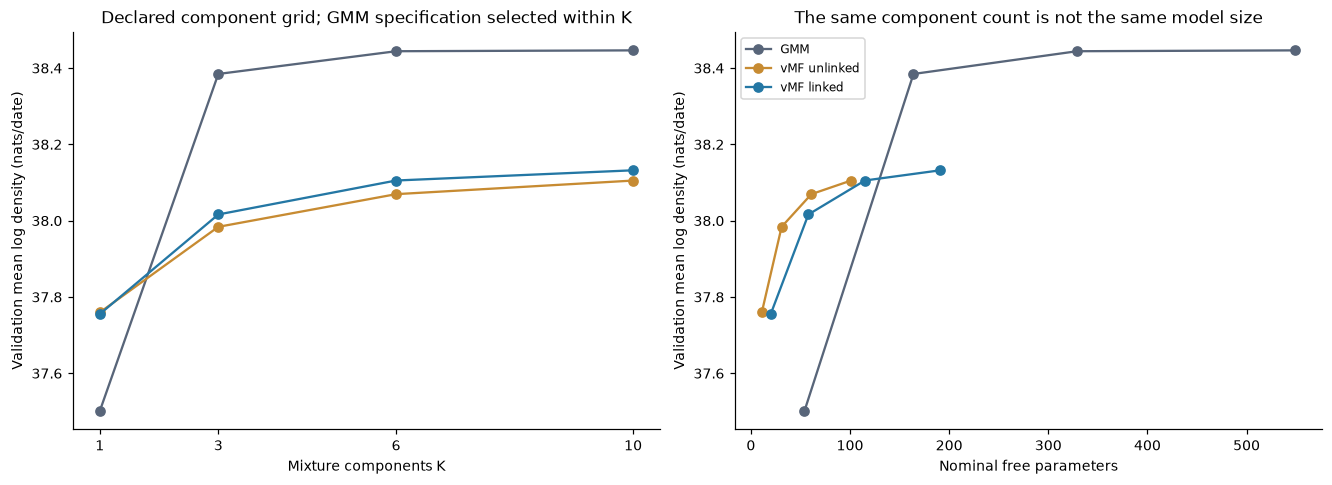

In [3]:
if ready:
    display(results['search'][['family','k','covariance','regularization','parameters',
                              'accepted_starts','status','validation_mean_loglik','elapsed_seconds',
                              'warm_preparation_seconds']].round(5))
    display(results['selection'][results['selection'].view == 'best_in_grid'])
    report.validation_figure(results)
    plt.show()


## 5. Same-component held-out comparisons

**Log score:** mean log density of the original FX return vectors; higher is better, in natural-log units (nats) per date.

**AIC/BIC:** $2p-2\ell$ and $p\log N-2\ell$, using total development likelihood, nominal parameter count $p$, and development observations $N$. Lower is better. They describe fitted-sample fit/complexity, not test accuracy. No test-bootstrap intervals are attached to these criteria.

**Uncertainty:** 1,500 paired circular block-bootstrap draws over complete test dates. The primary block is 20 sessions; 5 and 60 are sensitivity checks. Paired differences retain the same resampled dates for both models. Intervals are pointwise, conditional on fitted models, and not adjusted for model selection or multiple comparisons.

No ordinary chi-square likelihood-ratio test is used for zero anisotropy: tangent axes become unidentified at the isotropic limit, and finite mixtures introduce further nonregularity. The declared held-out paired log-score comparisons are the primary evidence.

Kent-minus-vMF isolates directional-family changes at the same K and radial specification. Linked-minus-unlinked assesses the direction–magnitude regression. Comparisons with GMM use the same Cartesian density measure. None of these scores establishes true regime labels or forecasting profitability.


,k,family,covariance,parameters,status,test_mean_loglik,test_lower_L20,test_upper_L20,aic,bic,accepted_starts,fit_seconds
0,1,GMM,tied,54.0,ok,38.03435,37.62916,38.41650,-402239.92618,-401882.91977,10.0,0.04700
1,1,vMF unlinked,scalar,11.0,ok,38.14896,37.65531,38.61638,-399628.91686,-399556.19333,10.0,0.01315
2,1,vMF linked,scalar,20.0,ok,38.15519,37.65978,38.62396,-399668.00143,-399535.77683,10.0,0.01756
3,1,Kent unlinked,NaN,46.0,no admissible validation fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,Kent linked,NaN,55.0,no admissible validation fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,3,GMM,full,164.0,ok,38.80744,38.33410,39.25596,-412763.83118,-411679.58948,10.0,2.64405
6,3,vMF unlinked,scalar,31.0,ok,38.55719,38.07529,39.01601,-404895.87500,-404690.92688,10.0,2.72865
7,3,vMF linked,scalar,58.0,ok,38.59481,38.11603,39.05038,-405444.62654,-405061.17521,10.0,5.68394
8,3,Kent unlinked,NaN,136.0,no admissible validation fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,3,Kent linked,NaN,163.0,no admissible validation fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN


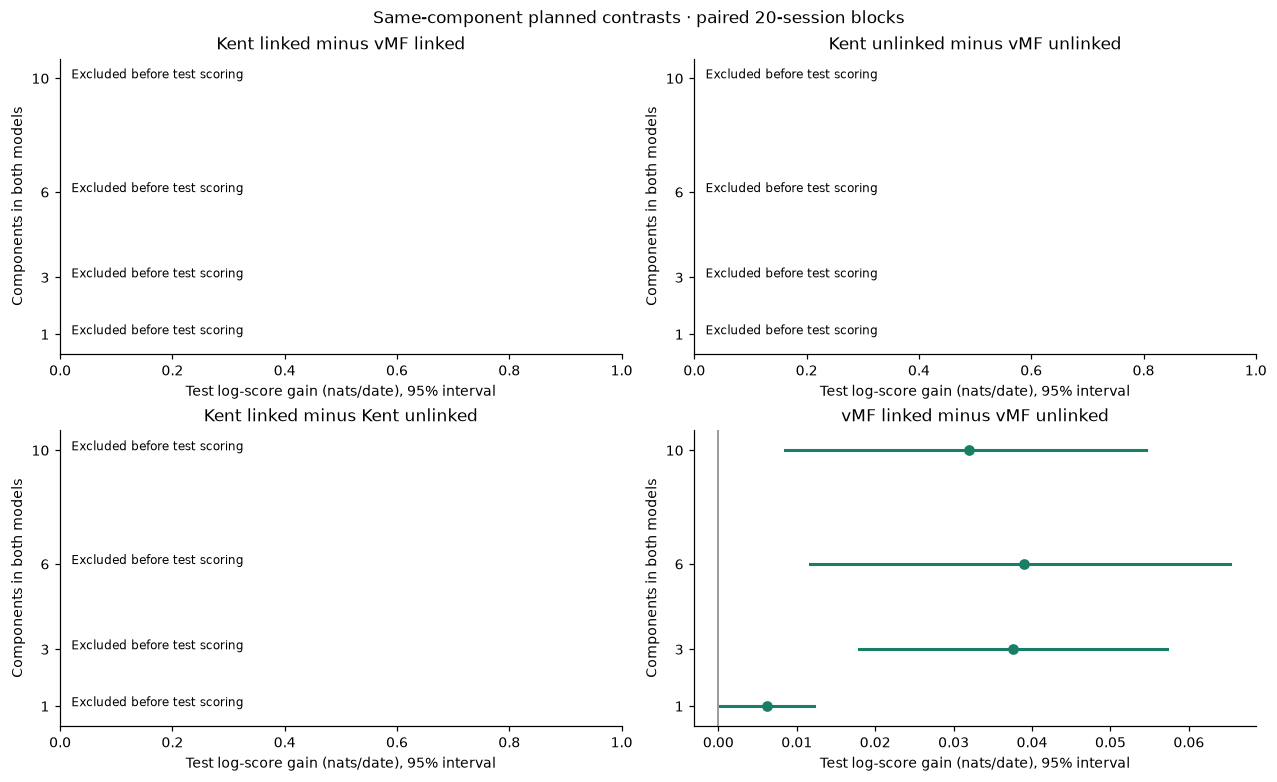

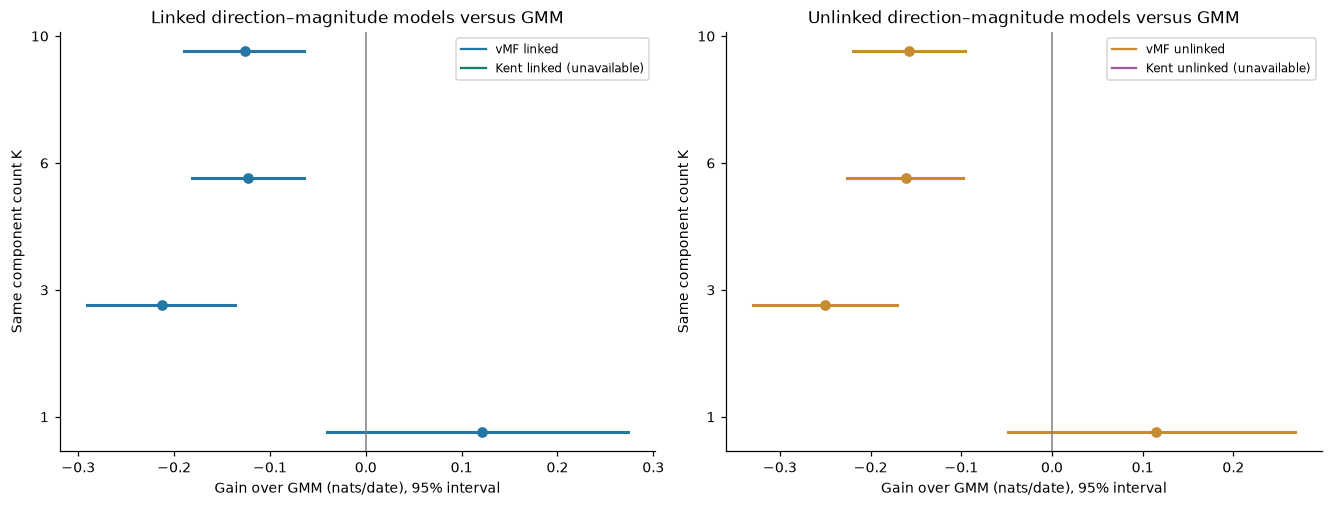

,view,candidate,reference,comparison,block,gain,lower,upper
0,same_K_1,vmf_linked_k01,vmf_unlinked_k01,vMF linked minus vMF unlinked,5,0.00624,0.00019,0.01227
1,same_K_1,vmf_linked_k01,vmf_unlinked_k01,vMF linked minus vMF unlinked,20,0.00624,0.00019,0.01224
2,same_K_1,vmf_linked_k01,vmf_unlinked_k01,vMF linked minus vMF unlinked,60,0.00624,0.00023,0.01260
3,same_K_1,vmf_unlinked_k01,gmm_k01_tied_1e-08,vMF unlinked minus GMM,5,0.11461,-0.01448,0.24377
4,same_K_1,vmf_unlinked_k01,gmm_k01_tied_1e-08,vMF unlinked minus GMM,20,0.11461,-0.04884,0.26770
5,same_K_1,vmf_unlinked_k01,gmm_k01_tied_1e-08,vMF unlinked minus GMM,60,0.11461,-0.12373,0.32840
6,same_K_1,vmf_linked_k01,gmm_k01_tied_1e-08,vMF linked minus GMM,5,0.12084,-0.00723,0.25145
7,same_K_1,vmf_linked_k01,gmm_k01_tied_1e-08,vMF linked minus GMM,20,0.12084,-0.04060,0.27387
8,same_K_1,vmf_linked_k01,gmm_k01_tied_1e-08,vMF linked minus GMM,60,0.12084,-0.11784,0.33627
9,same_K_3,vmf_linked_k03,vmf_unlinked_k03,vMF linked minus vMF unlinked,5,0.03762,0.01762,0.05863


In [4]:
if ready:
    display(report.same_component_table(results).round(5))
    report.same_k_figure(results)
    plt.show()
    report.baseline_figure(results)
    plt.show()
    display(results['contrasts'][results['contrasts'].view.str.startswith('same_K')].round(5))


## 6. Equal-parameter and approximately matched comparisons

Exact matches are shown where feasible. Approximate budget windows require maximum/minimum parameter count ≤1.10; validation selects the available family configuration in each window, and duplicate selections are removed. A window need not contain every family.

For this grid, **no unlinked Kent–vMF match exists within 10%**. The only linked match is Kent K=1 (55 parameters) versus vMF K=3 (58 parameters), and is usable only if both fits are admissible. No extra K values are fitted to fill missing comparisons. Exact matching of nominal counts does not make the statistical models equally expressive.


,comparison,left_k,right_k,left_parameters,right_parameters,ratio,status
0,Kent linked versus vMF linked,1.0,3.0,55.0,58.0,1.05455,structural match; inadmissible fit
1,Kent unlinked versus vMF unlinked,NaN,NaN,NaN,NaN,NaN,no parameter match within 10% in declared grid
2,Kent linked versus GMM,1.0,1.0,55.0,54.0,1.01852,structural match; inadmissible fit
3,Kent linked versus GMM,1.0,1.0,55.0,54.0,1.01852,structural match; inadmissible fit
4,Kent linked versus GMM,1.0,3.0,55.0,56.0,1.01818,structural match; inadmissible fit
5,Kent linked versus GMM,3.0,3.0,163.0,164.0,1.00613,structural match; inadmissible fit
6,Kent linked versus GMM,6.0,6.0,325.0,329.0,1.01231,structural match; inadmissible fit
7,Kent linked versus GMM,10.0,10.0,541.0,549.0,1.01479,structural match; inadmissible fit
8,Kent unlinked versus GMM,3.0,10.0,136.0,144.0,1.05882,structural match; inadmissible fit


,view,family,k,parameters,status,test_mean_loglik,aic,bic
0,budget10_10_11,GMM,1,10,ok,36.87626,-387012.57985,-386946.46755
1,budget10_10_11,vMF unlinked,1,11,ok,38.14896,-399628.91686,-399556.19333
2,budget10_31_34,GMM,3,32,ok,38.12462,-399778.69494,-399567.13558
3,budget10_31_34,vMF unlinked,3,31,ok,38.55719,-404895.87500,-404690.92688
4,budget10_54_59,GMM,3,56,ok,38.03608,-401736.00105,-401365.77218
5,budget10_54_59,vMF linked,3,58,ok,38.59481,-405444.62654,-405061.17521
6,budget10_56_61,GMM,3,56,ok,38.03608,-401736.00105,-401365.77218
7,budget10_56_61,vMF unlinked,6,61,ok,38.71229,-406993.37072,-406590.08570
8,budget10_56_61,vMF linked,3,58,ok,38.59481,-405444.62654,-405061.17521
9,budget10_58_63,vMF unlinked,6,61,ok,38.71229,-406993.37072,-406590.08570


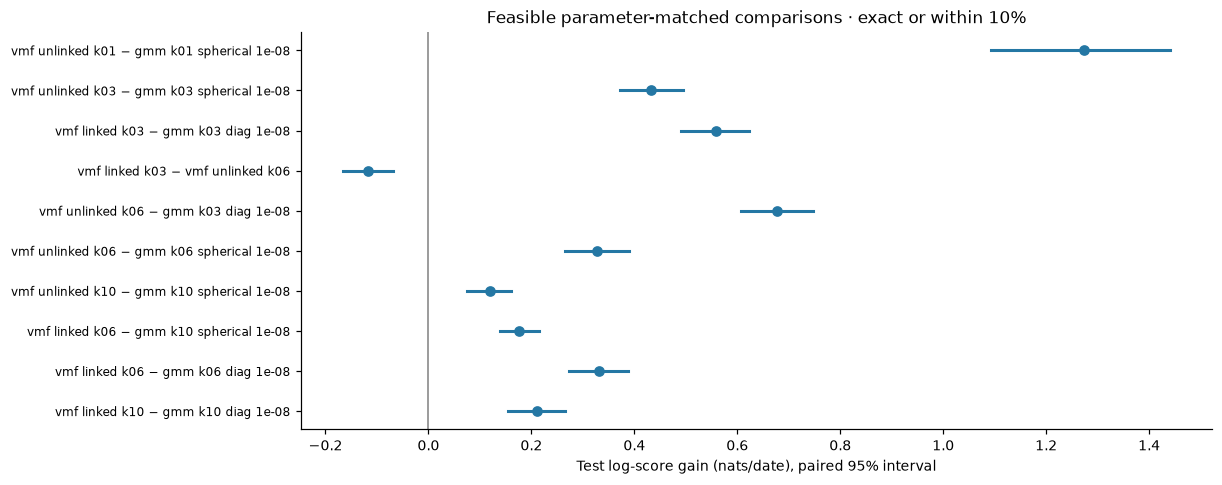

,view,candidate,reference,comparison,block,gain,lower,upper
45,budget10_10_11,vmf_unlinked_k01,gmm_k01_spherical_1e-08,vMF unlinked minus GMM,5,1.27269,1.14688,1.40427
46,budget10_10_11,vmf_unlinked_k01,gmm_k01_spherical_1e-08,vMF unlinked minus GMM,20,1.27269,1.09274,1.44136
47,budget10_10_11,vmf_unlinked_k01,gmm_k01_spherical_1e-08,vMF unlinked minus GMM,60,1.27269,1.02813,1.50055
48,budget10_31_34,vmf_unlinked_k03,gmm_k03_spherical_1e-08,vMF unlinked minus GMM,5,0.43257,0.37669,0.48919
49,budget10_31_34,vmf_unlinked_k03,gmm_k03_spherical_1e-08,vMF unlinked minus GMM,20,0.43257,0.37132,0.49352
50,budget10_31_34,vmf_unlinked_k03,gmm_k03_spherical_1e-08,vMF unlinked minus GMM,60,0.43257,0.35751,0.50929
51,budget10_54_59,vmf_linked_k03,gmm_k03_diag_1e-08,vMF linked minus GMM,5,0.55873,0.49999,0.61446
52,budget10_54_59,vmf_linked_k03,gmm_k03_diag_1e-08,vMF linked minus GMM,20,0.55873,0.49006,0.62330
53,budget10_54_59,vmf_linked_k03,gmm_k03_diag_1e-08,vMF linked minus GMM,60,0.55873,0.47388,0.63700
54,budget10_56_61,vmf_linked_k03,vmf_unlinked_k06,vMF linked minus vMF unlinked,5,-0.11749,-0.15992,-0.07356


In [5]:
if ready:
    display(report.comparison_feasibility(results).round(5))
    display(report.budget_table(results).round(5))
    report.budget_figure(results)
    plt.show()
    display(results['contrasts'][results['contrasts'].view.str.startswith(('budget10','exact'))].round(5))


## 7. Runtime, convergence, and numerical rejection

Training fits are timed freshly with one numerical-library thread. Baselines call the original estimator with timing/trace hooks verified to preserve fitted scores. GMM traces require an additional score evaluation per iteration, so recorded runtimes include that instrumentation overhead. GMM covariance regularization need not give strictly monotone unpenalized likelihood.

The runtime chart includes rejected starts; GMM uses its validation-selected covariance/regularization at each K. Per-start timings cover the instrumented fit routines and exclude shared K-means responsibility construction. Separate ledgers retain configuration totals and warm-start preparation costs. An EM iteration is not a fixed unit of work: Kent additionally performs numerical normalization, constrained shape optimization, and frame updates.

Convergence curves show within-start gaps to final training likelihood. Dashed curves are rejected training fits, displayed diagnostically rather than promoted to evaluated candidates. Development fit timings are also in the main score table.


starts  converged  ...  median_iterations  normalization_seconds
family        k                      ...                                          
GMM           1      120        120  ...                2.0                 0.0000
              3      120        120  ...               75.0                 0.0000
              6      120         84  ...              115.0                 0.0000
              10     120         68  ...              118.0                 0.0000
Kent linked   1       10         10  ...                5.0                 1.8815
              3       10         10  ...               85.0                60.8720
              6       10         10  ...              185.0               689.3096
              10      10          7  ...              300.0              2503.5518
Kent unlinked 1       10         10  ...                5.0                 1.8761
              3       10         10  ...              128.5               117.6544
              6       10         10  ...              175.5               692.2285
              10      10         10  ...              208.0              1939.3778
vMF linked    1       10         10  ...                1.0                 0.0000
              3       10         10  ...              112.5                 0.0000
              6       10         10  ...              127.0                 0.0000
              10      10          9  ...              187.0                 0.0000
vMF unlinked  1       10         10  ...                1.0                 0.0000
              3       10         10  ...              259.0                 0.0000
              6       10         10  ...              150.5                 0.0000
              10      10         10  ...              167.5                 0.0000

[20 rows x 6 columns]

,family,k,status,boundary_reasons,starts
0,GMM,6,FloatingPointError: Collapsed GMM component,,36
1,GMM,10,FloatingPointError: Collapsed GMM component,,48
2,GMM,10,nonconverged,,4
3,Kent linked,1,boundary,unimodality_margin,10
4,Kent linked,3,boundary,unimodality_margin,10
5,Kent linked,6,boundary,unimodality_margin,10
6,Kent linked,10,boundary,unimodality_margin,10
7,Kent unlinked,1,boundary,unimodality_margin,10
8,Kent unlinked,3,boundary,unimodality_margin,10
9,Kent unlinked,6,boundary,unimodality_margin,10


shape_iterations  ...  normalizer_failures
family        k                     ...                     
Kent linked   1               1008  ...                    0
              3              10360  ...                    0
              6              61040  ...                    0
              10            137584  ...                    0
Kent unlinked 1               1008  ...                    0
              3              18436  ...                    0
              6              61522  ...                    0
              10            106972  ...                    0

[8 rows x 6 columns]

,id,calls,seconds,nodes,max_error,failures
0,kent_linked_k01,1145,1.881570,4527185,2.296829e-12,0
1,kent_linked_k03,35292,60.872086,144099684,2.479794e-12,0
2,kent_linked_k06,390888,689.309697,1600484856,2.707168e-12,0
3,kent_linked_k10,1446830,2503.552097,5926023710,2.859935e-12,0
4,kent_unlinked_k01,1145,1.876119,4527185,2.296829e-12,0
5,kent_unlinked_k03,68316,117.654476,279399012,2.480682e-12,0
6,kent_unlinked_k06,395502,692.228677,1619388414,2.716050e-12,0
7,kent_unlinked_k10,1117880,1939.377973,4578315560,2.872369e-12,0


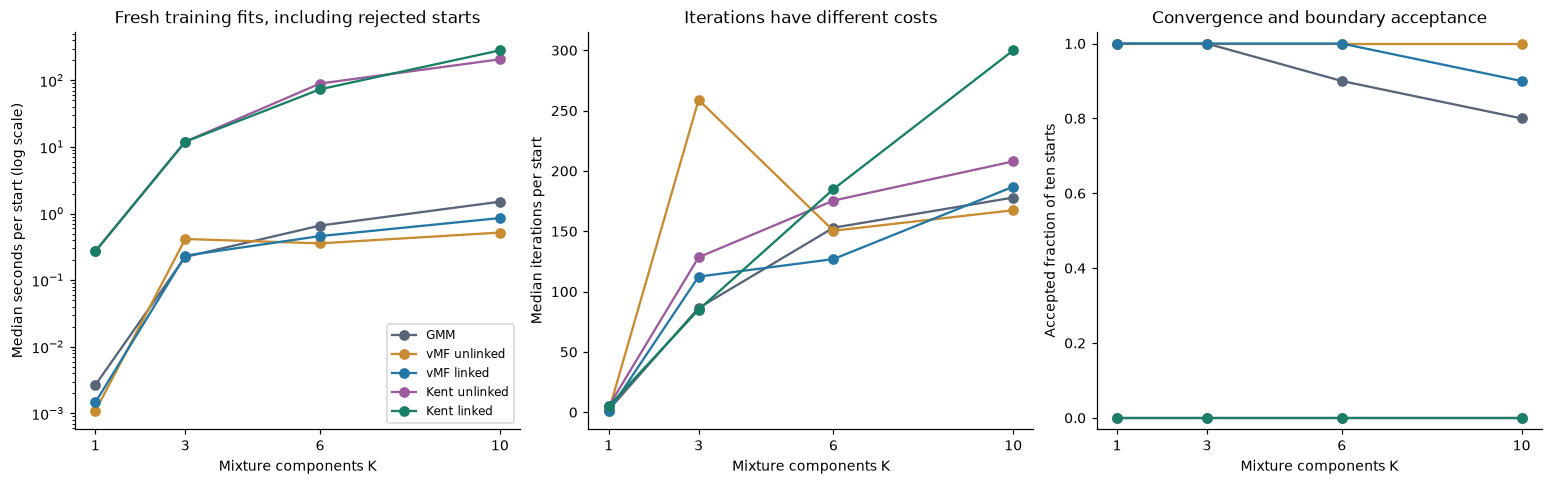

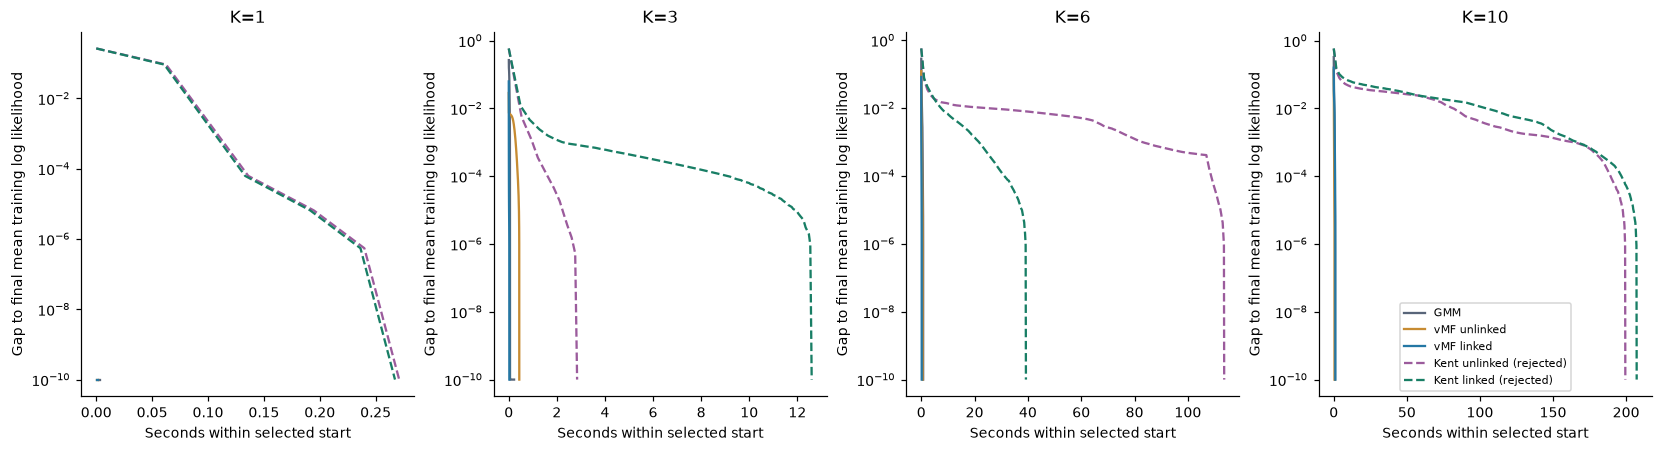

In [6]:
if ready:
    starts = report.search_starts(results)
    display(starts.groupby(['family','k']).agg(starts=('start','size'),converged=('converged','sum'),accepted=('accepted','sum'),
             median_seconds=('seconds','median'),median_iterations=('iterations','median'),
             normalization_seconds=('normalizer_seconds','sum')).round(4))
    rejected = starts[~starts.accepted]
    display(rejected.groupby(['family','k','status','boundary_reasons'],dropna=False).size().rename('starts').reset_index())
    display(starts[starts.family.str.startswith('Kent')].groupby(['family','k'])[
        ['shape_iterations','shape_evaluations','frame_iterations','frame_evaluations',
         'normalizer_calls','normalizer_failures']].sum())
    display(report.normalization_run_summary(results))
    report.runtime_figure(results)
    plt.show()
    report.convergence_figure(results)
    plt.show()


## 8. What anisotropy was fitted?

The diagnostic heatmaps show $2\lambda_j/\kappa$ for ordered tangent eigenvalues. Zero means isotropy in that quadratic coefficient; the largest permitted ratio is approximately one. Rows are annotated by training mixture weight, not economic labels.

For a concentrated interior component, the local tangent Gaussian approximation has variances $(\kappa-2\lambda_j)^{-1}$. The exported largest/smallest variance ratio is approximate and becomes unreliable near the unimodality boundary. The heatmap can include the best rejected training fit, explicitly labeled. Such a fit is not evaluated on test data.

Directional and conditional-magnitude log scores decompose the joint cylindrical score for admissible directional models. They describe which distributional block changes; they are not directly comparable with a GMM Cartesian joint score.


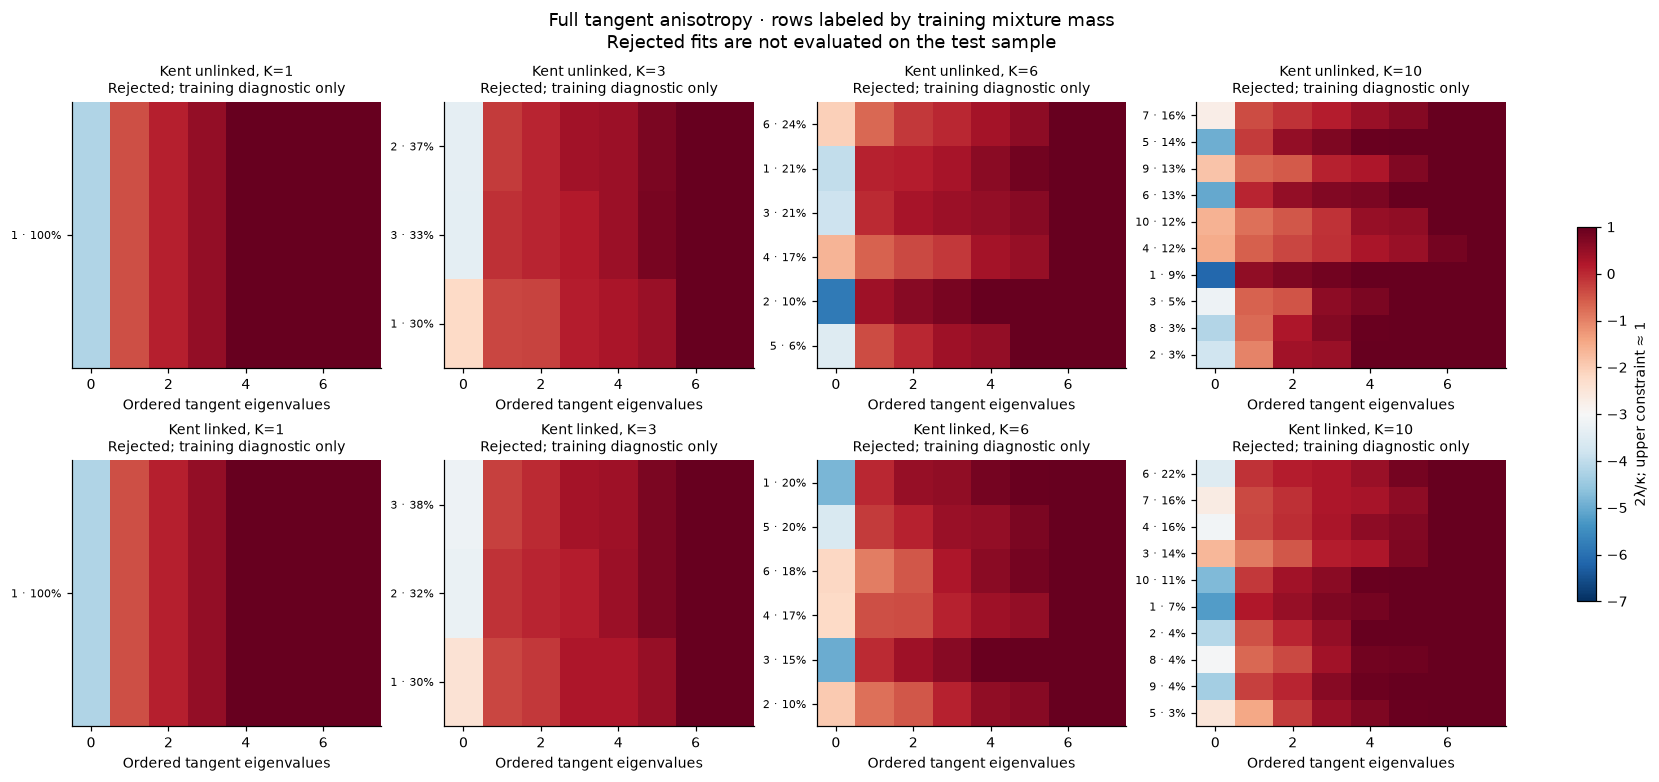

,id,accepted,component,training_mass,kappa,max_ovalness,local_variance_ratio
0,kent_unlinked_k01,False,0,1.00000,1.83390,1.0,5.210117e+06
1,kent_unlinked_k03,False,1,0.37238,7.80703,1.0,4.355118e+06
2,kent_unlinked_k03,False,2,0.32999,7.80703,1.0,4.378693e+06
3,kent_unlinked_k03,False,0,0.29763,7.80703,1.0,3.212437e+06
4,kent_unlinked_k06,False,5,0.24073,9.86393,1.0,3.051855e+06
5,kent_unlinked_k06,False,0,0.21299,9.86393,1.0,4.981269e+06
6,kent_unlinked_k06,False,2,0.20841,9.86393,1.0,4.819816e+06
7,kent_unlinked_k06,False,3,0.17186,9.86393,1.0,2.634593e+06
8,kent_unlinked_k06,False,1,0.10208,9.86393,1.0,6.836744e+06
9,kent_unlinked_k06,False,4,0.06393,9.86393,1.0,4.513474e+06


,id,family,k,direction_log_score,conditional_magnitude_log_score
0,vmf_unlinked_k01,vMF unlinked,1,-3.38677,-0.76574
1,vmf_linked_k01,vMF linked,1,-3.38677,-0.75950
2,vmf_unlinked_k03,vMF unlinked,3,-2.98250,-0.76178
3,vmf_linked_k03,vMF linked,3,-2.97937,-0.72729
4,vmf_unlinked_k06,vMF unlinked,6,-2.83101,-0.75816
5,vmf_linked_k06,vMF linked,6,-2.82973,-0.72051
6,vmf_unlinked_k10,vMF unlinked,10,-2.84746,-0.75955
7,vmf_linked_k10,vMF linked,10,-2.84689,-0.72817


In [7]:
if ready:
    report.anisotropy_figure(results)
    plt.show()
    display(pd.read_csv(run_dir / 'anisotropy_summary.csv').round(5))
    display(results['decomposition'].round(5))


## 9. Findings and limits

| Issue | Interpretation |
|---|---|
| Original-space data | No embedding distortion is introduced; FX coordinates and original log magnitudes are unchanged. |
| Full anisotropy | Kent has substantially more parameters per component; equal K does not control capacity. |
| Shared concentration/variance | This pilot matches the original shared baseline, not the later sharing ablation. |
| Numerical optimization | Kent is generalized EM with local numerical updates; global optimality is not guaranteed. |
| Boundary rejection | A constrained optimum at the shape boundary can be statistically meaningful, but is inadmissible under this declared pilot. No silent relaxation occurs. |
| Initialization | Matched seeds do not eliminate optimization differences; Kent has explicit nested warm starts. |
| Search budget | Each directional family has four configurations; GMM has 48 covariance/regularization/K configurations. Ten starts per configuration does not equalize total search effort. |
| Parameter matching | Some comparisons are structurally unavailable; no grid or tolerance is widened after seeing outcomes. |
| AIC/BIC | Nominal counts, mixture singularities, and serial dependence limit classical interpretations. |
| Test reuse | The historical period was previously inspected; this is retrospective evidence. |
| Static mixtures | This is density estimation, without regime transitions or a trading strategy. |

The statements below are generated from saved results. If the numerical gate passes but Kent fits are inadmissible, that is a limitation of this declared pilot—not evidence that vMF universally dominates anisotropic distributions.


In [8]:
if ready:
    display(Markdown(report.conclusions(results)))
    print('Full artifacts:', run_dir)


Full artifacts: /Users/shashwatroy/VSCode Projects/Thesis/Kent mixture models/results/a9f01047734a8126


**No admissible generalized Kent fit survived the declared validation-stage rules.** Consequently this pilot does not establish whether Kent improves held-out fit. Boundary-rejected training fits are shown only as diagnostics; they are not scored on test dates.

Across 80 Kent starts, 77 met the convergence criterion, 80 reached the shape margin, and 0 were admissible. The recorded number of normalization failures was 0.

**Why no Kent test scores?** The frozen protocol excluded fits with an active shape constraint. This is an acceptance-policy decision, not evidence that those normalized densities are invalid. It prevented the intended directional-family comparison. A revised analysis should retain converged, numerically valid fits at the existing shape margin, flag that constraint, and still exclude nonconvergence and genuine numerical failures. That revised analysis has not been run here.

**Validation-selected models within the declared grid:**
- GMM: K=10, 549 parameters; test log score 38.8522.
- vMF unlinked: K=10, 101 parameters; test log score 38.6945.
- vMF linked: K=10, 191 parameters; test log score 38.7264.

A validation winner at K=10 is at the upper grid boundary, not evidence that 10 is optimal.

11 of 64 search configurations were unavailable. Rejected starts and selected-refit failures remain in the ledgers.

The unlinked Kent–vMF parameter match is unavailable within 10%. The linked match uses Kent K=1 and vMF K=3 (55 versus 58 parameters), subject to admissible fits. These tests concern retrospective density fit, not recovery of true regimes or trading profitability.

## 10. Saved-model boundary-inclusive test evaluation

This user-requested follow-up accepts the eight saved converged Kent fits at the imposed shape margin. No fitting was performed. Full parameters were saved for one best training-likelihood Kent fit per configuration, not all 80 starts. All eight saved candidates converged.

The primary comparison uses training-only checkpoints for **all five families**, with identical original FX inputs and 1,374 test dates. GMM covariance/regularization uses the original validation selection within K. Kent candidates were selected by training likelihood. The earlier main tables use development-refitted baselines and must not be directly compared with these training-only Kent scores.

Intervals use 1,500 paired circular block-bootstrap draws, with 20 sessions primary and 5/60 sensitivity. AIC/BIC here use **training likelihood and training N**, not development likelihood. Nominal parameter counts and boundary estimates limit classical interpretations. This amendment follows inspection of boundary outcomes; the test period is retrospective. There is no claim of a fresh confirmatory test.

The strict positive test is $2\max_j\lambda_j<\kappa$. The stronger all-axis test is $2\max_j|\lambda_j|<\kappa$. These are different restrictions. Passing the first does not establish monotonic decrease along every great circle. K counts mixture components, not verified economic regimes.


,id,family,k,parameters,test_log_score,training_aic,training_bic,lower,upper
0,gmm_k01_tied_1e-08,GMM,1,54,37.839170,-298857.253496,-298515.778641,37.451729,38.204495
1,vmf_unlinked_k01,vMF unlinked,1,11,38.094179,-295872.493351,-295802.933658,37.613885,38.549656
2,vmf_linked_k01,vMF linked,1,20,38.095157,-295915.525898,-295789.053729,37.613320,38.551491
3,kent_unlinked_k01,Kent unlinked,1,46,38.239417,-297989.765042,-297698.879053,37.768753,38.693513
4,kent_linked_k01,Kent linked,1,55,38.240395,-298032.797589,-297684.999124,37.770228,38.694143
5,gmm_k03_full_1e-07,GMM,3,164,38.609963,-306976.822494,-305939.750710,38.138166,39.054346
6,vmf_unlinked_k03,vMF unlinked,3,31,38.436087,-300406.441461,-300210.409599,37.966310,38.875236
7,vmf_linked_k03,vMF linked,3,58,38.474505,-300866.596601,-300499.827312,38.006060,38.916518
8,kent_unlinked_k03,Kent unlinked,3,136,38.618016,-304748.935624,-303888.924876,38.153823,39.063715
9,kent_linked_k03,Kent linked,3,163,38.641590,-305213.332791,-304182.584615,38.174578,39.094670


,k,comparison,block,gain,lower,upper
0,1,Kent linked minus vMF linked,5,0.145238,0.114911,0.175709
1,1,Kent unlinked minus vMF unlinked,5,0.145238,0.114911,0.175709
2,1,Kent linked minus Kent unlinked,5,0.000978,-0.006166,0.008832
3,1,vMF linked minus vMF unlinked,5,0.000978,-0.006166,0.008832
4,1,vMF unlinked minus GMM,5,0.255008,0.126421,0.380208
...,...,...,...,...,...,...
91,10,vMF linked minus vMF unlinked,60,0.026582,-0.013487,0.061132
92,10,vMF unlinked minus GMM,60,-0.101776,-0.173146,-0.024511
93,10,vMF linked minus GMM,60,-0.075194,-0.137795,-0.008443
94,10,Kent unlinked minus GMM,60,-0.169544,-0.245384,-0.094613


,id,k,component,kappa,max_ratio,absolute_ratio,strict_positive,strict_absolute
0,kent_unlinked_k01,1,0,1.833896,0.999999,4.210117,True,False
1,kent_linked_k01,1,0,1.833896,0.999999,4.210117,True,False
2,kent_unlinked_k03,3,0,7.807031,0.999999,2.212437,True,False
3,kent_unlinked_k03,3,1,7.807031,0.999999,3.355118,True,False
4,kent_unlinked_k03,3,2,7.807031,0.999999,3.378693,True,False
5,kent_linked_k03,3,0,7.792807,0.999999,2.436226,True,False
6,kent_linked_k03,3,1,7.792807,0.999999,3.278282,True,False
7,kent_linked_k03,3,2,7.792807,0.999999,3.206440,True,False
8,kent_unlinked_k06,6,0,9.863928,0.999999,3.981269,True,False
9,kent_unlinked_k06,6,1,9.863928,0.999999,5.836744,True,False


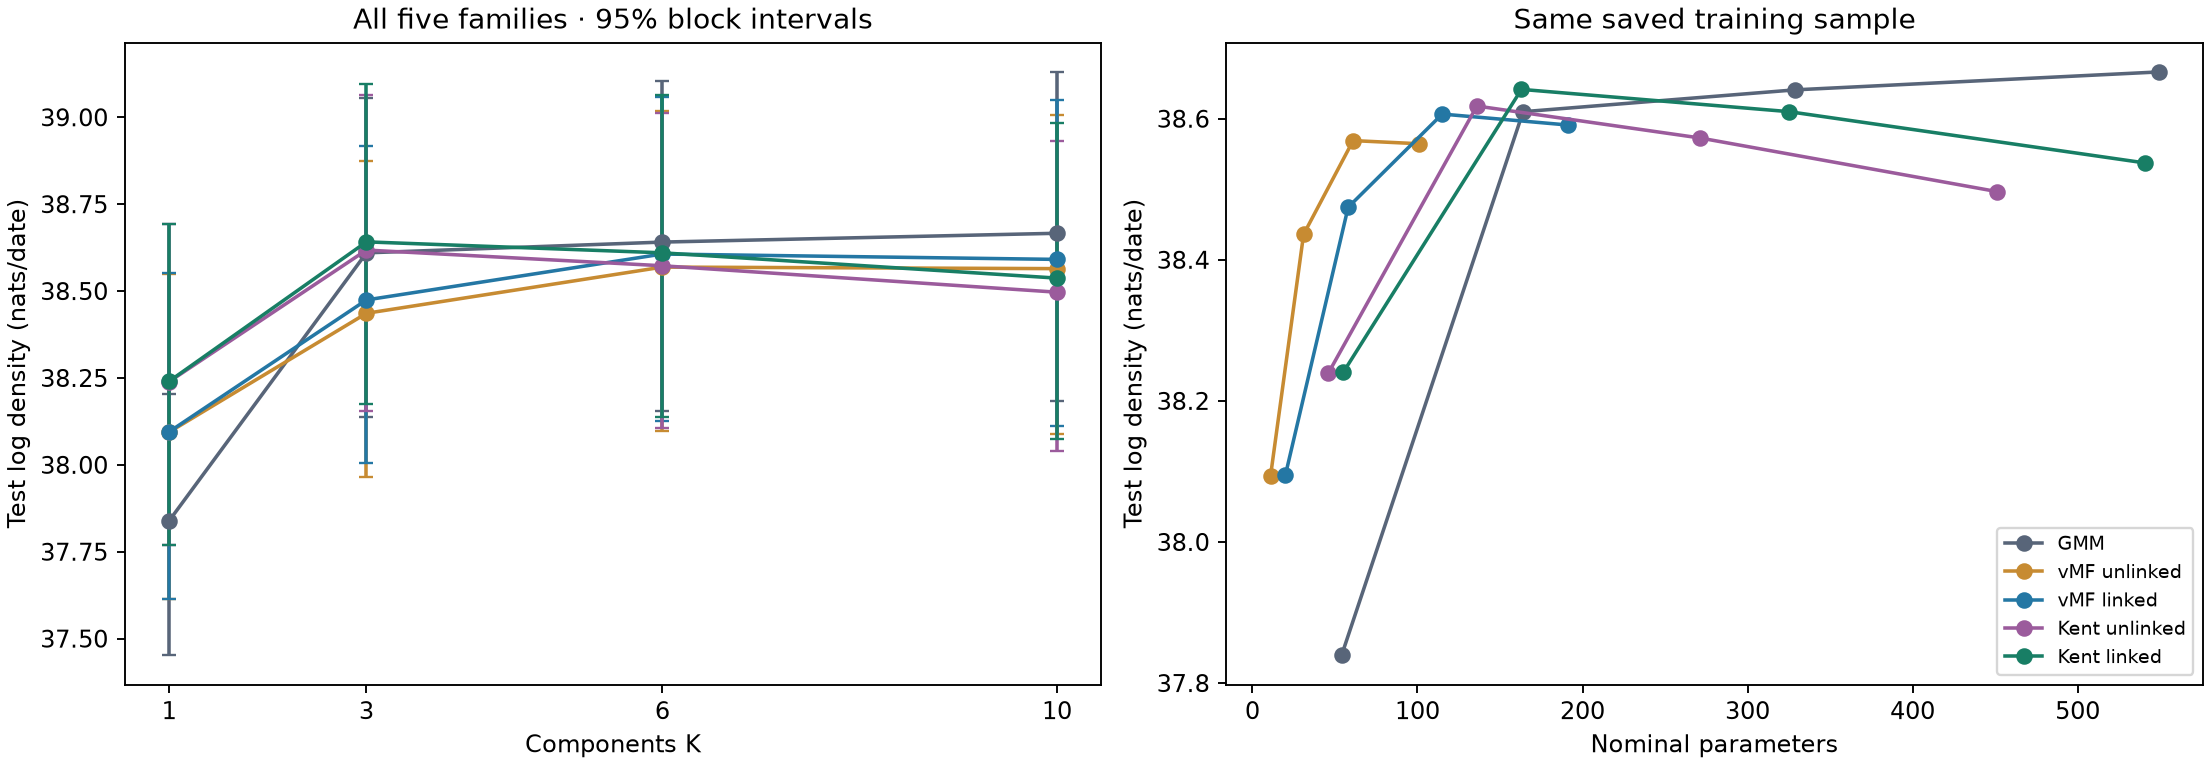

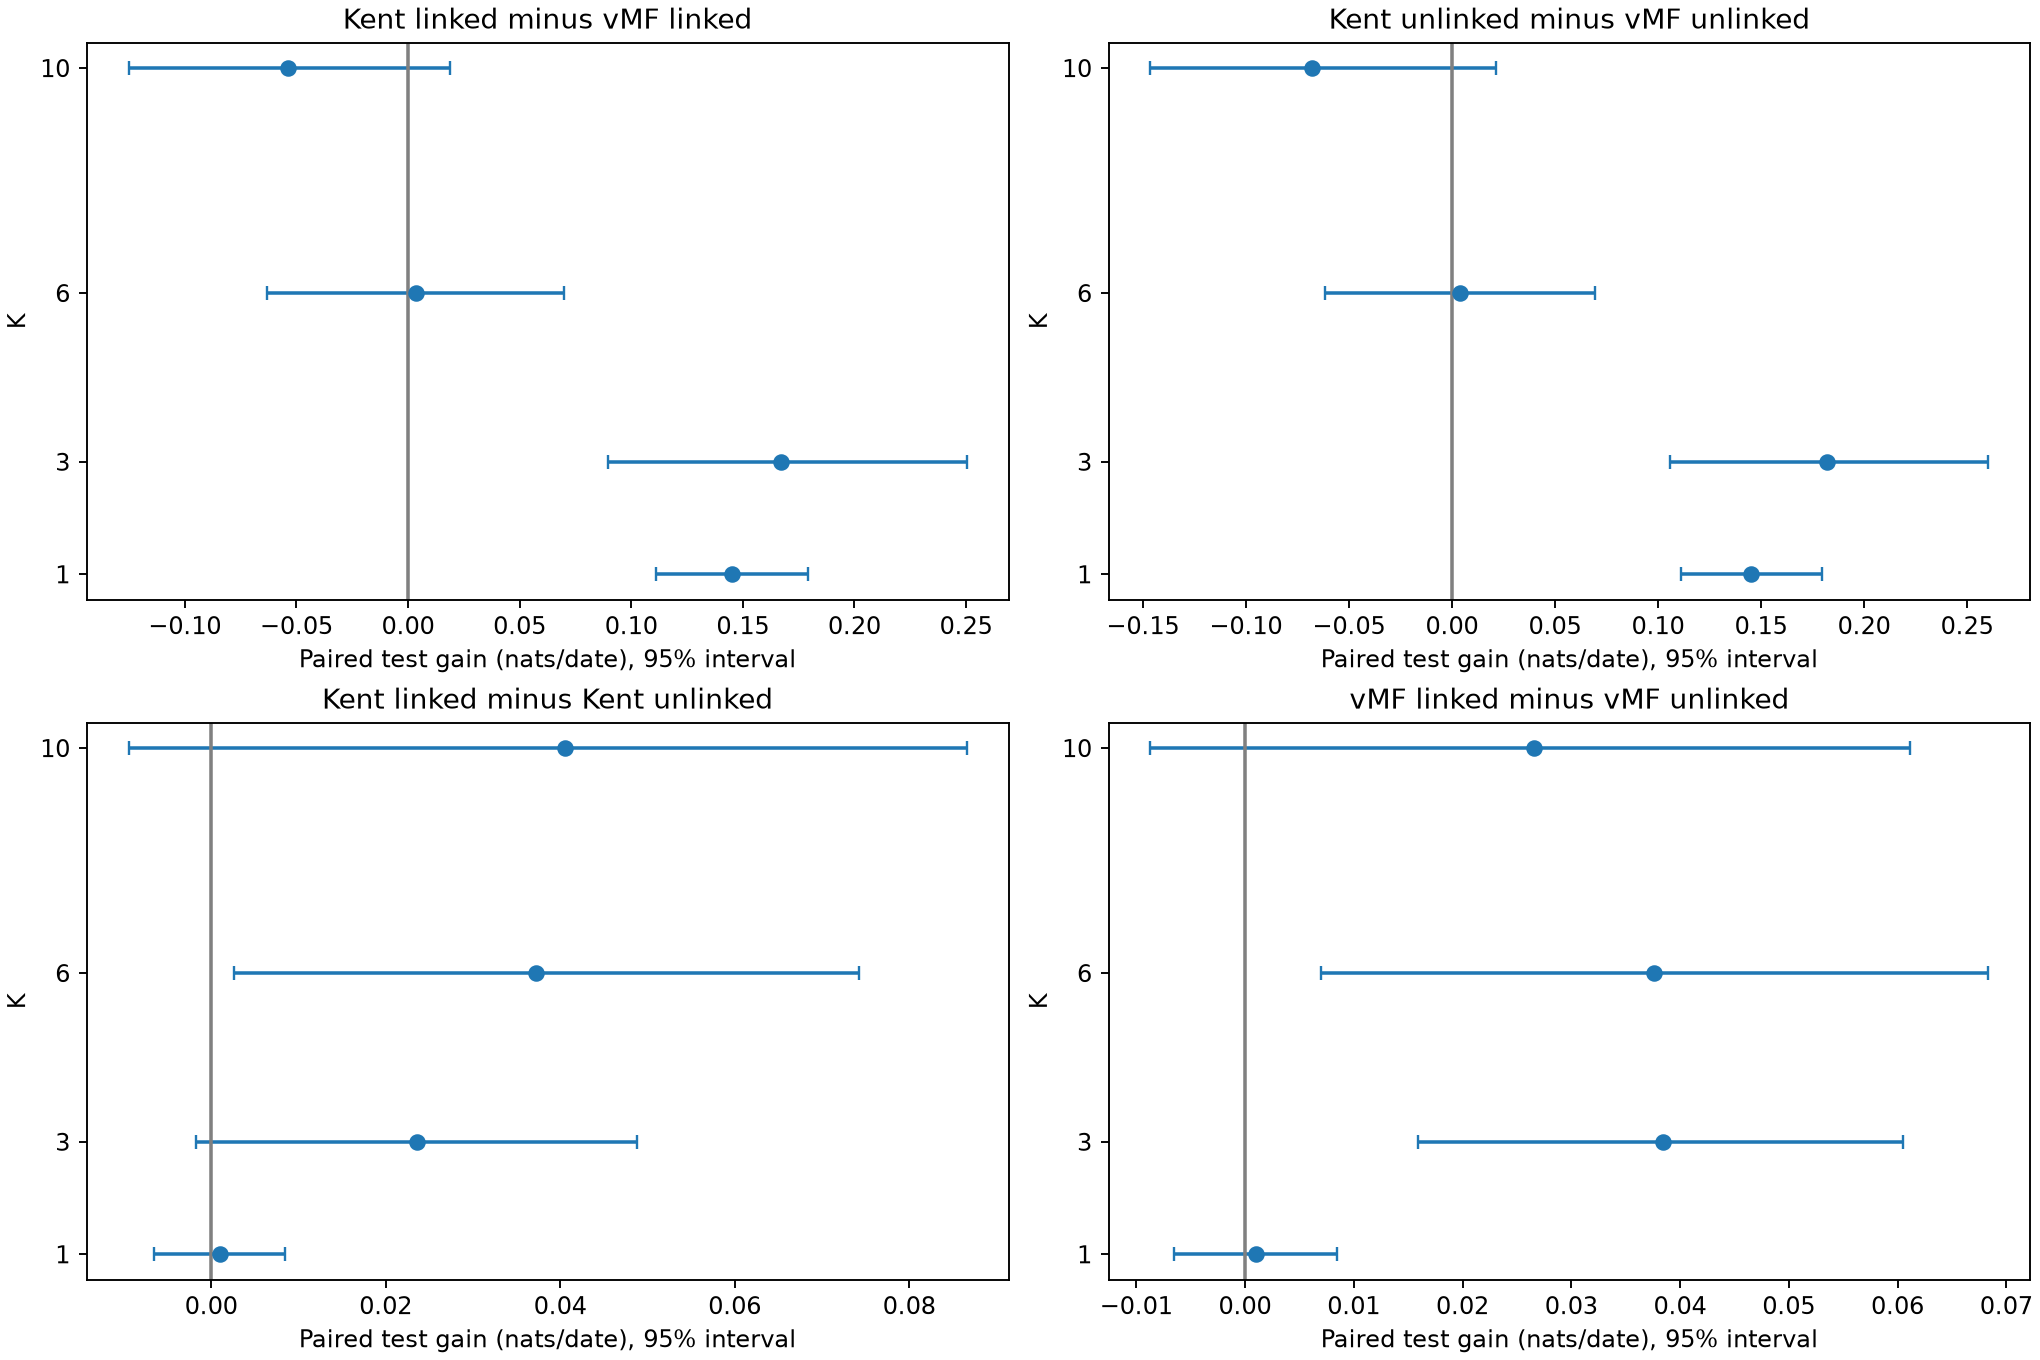

In [9]:
from evaluate_saved import show_saved
show_saved()